# 3. Plots

This notebook draws the box plots and scatter plots in the preprint paper.

In the box plots, the box spans the 25th to 75th percentiles, and the black line is the median.
The whiskers reach the furthest prefecture within 1.5 times the interquartile range beyond the box.
Every prefecture is drawn as a point.
In the scatter plots, "Has Plant" means that the prefecture has at least one operable (not yet retired) reactor.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import seaborn as sns

DATA = Path("../data")
plt.rcParams.update({
    "font.family": "sans-serif", "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
    "font.size": 7, "axes.titlesize": 7, "axes.labelsize": 7, "xtick.labelsize": 7, "ytick.labelsize": 7,
    "legend.fontsize": 7, "legend.title_fontsize": 7,
    "axes.linewidth": 0.6, "xtick.major.width": 0.6, "ytick.major.width": 0.6,
    "xtick.major.size": 2.5, "ytick.major.size": 2.5,
    "figure.dpi": 150,
})

prefectures = pd.read_csv(DATA / "prefectures.csv")
d = prefectures[prefectures["prefecture"] != "Fukushima"]   # Fukushima excluded
pre = prefectures.assign(group=prefectures["host_2004-2010"].map({1: "Host", 0: "No-host"}) + " / "
                         + prefectures["border_2004-2010"].map({1: "Border", 0: "No-border"}))
values = {g: rows["search_interest_2004-2010"] for g, rows in pre.groupby("group")}
POST = [("2012-2014", "Shutdown (2012–2014)"), ("2015-2019", "Initial restart (2015–2019)"), ("2020-2024", "Recent (2020–2024)")]

In [2]:
def box_points(ax, groups, positions, colors, width, size):
    for pos, vals, color in zip(positions, groups, colors):
        vals = np.asarray(vals, dtype=float)
        ax.boxplot([vals], positions=[pos], widths=width, patch_artist=True, showcaps=True, showfliers=False, whis=1.5,
                   capwidths=width * 0.45, boxprops=dict(facecolor=color, edgecolor="0.35", linewidth=0.6),
                   medianprops=dict(color="black", linewidth=1.0), whiskerprops=dict(color="black", linewidth=0.8),
                   capprops=dict(color="black", linewidth=0.8), zorder=2)
        ax.scatter(np.full(len(vals), float(pos)), vals, s=size, facecolors="white", edgecolors="black",
                   linewidths=0.6, zorder=3)

def distance_scatter(ax, period, ylabel, marker_size):
    s = d.assign(Has_Plant=d[f"host_{period}"].map({1: "Yes", 0: "No"}))
    sns.scatterplot(x="distance_km", y=f"search_interest_{period}", data=s, hue="Has_Plant", style="Has_Plant",
                    hue_order=["Yes", "No"], style_order=["Yes", "No"],
                    palette={"No": "#faf7db", "Yes": "#000568"}, markers={"No": "o", "Yes": "^"},
                    s=marker_size, alpha=0.7, edgecolor="black", linewidth=0.5, zorder=3, ax=ax)
    leg = ax.legend(title="Has Plant", loc="upper right", frameon=True, facecolor="white", edgecolor="black",
                    handletextpad=0.3, borderpad=0.4, labelspacing=0.3, fancybox=False)
    leg.get_frame().set_linewidth(0.6)
    ax.set_ylim(10, 105)
    ax.set_xlabel("Distance from Fukushima (km)")
    ax.set_ylabel(ylabel)
    ax.grid(True, linestyle="--", alpha=0.6, linewidth=0.5)
    ax.set_axisbelow(True)

### Figure 1b: Search Interest by host and border status, 2004–2010

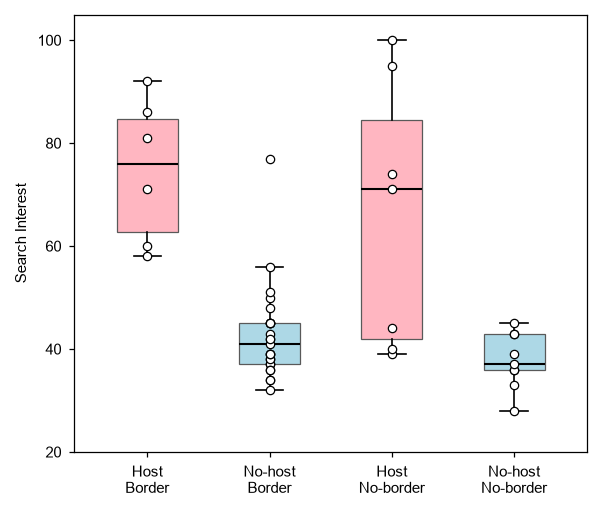

In [3]:
ORDER = ["Host / Border", "No-host / Border", "Host / No-border", "No-host / No-border"]
fig, ax = plt.subplots(figsize=(3.9, 3.3), layout="constrained")
box_points(ax, [values[g] for g in ORDER], range(4), ["lightpink" if g.startswith("Host") else "lightblue" for g in ORDER],
           width=0.5, size=16)
ax.set_xticks(range(4), [g.replace(" / ", "\n") for g in ORDER])
ax.set_xlim(-0.6, 3.6)
ax.set_ylim(20, 105)
ax.set_yticks([20, 40, 60, 80, 100])
ax.set_ylabel("Search Interest")
plt.show()

### Figure 2b: Search Interest by host status, 2011 (Fukushima excluded)

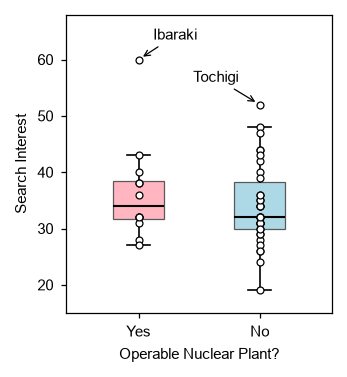

In [4]:
fig, ax = plt.subplots(figsize=(2.2, 2.4), layout="constrained")
box_points(ax, [d.loc[d["host_2011"] == h, "search_interest_2011"] for h in (1, 0)], [0, 1], ["lightpink", "lightblue"],
           width=0.42, size=11)
for name, x, dx, dy in [("Ibaraki", 0, 0.12, 3), ("Tochigi", 1, -0.55, 3.5)]:   # the two prefectures named in the text
    y = float(d.loc[d["prefecture"] == name, "search_interest_2011"].iloc[0])
    ax.annotate(name, xy=(x, y), xytext=(x + dx, y + dy), ha="left", va="bottom",
                arrowprops=dict(arrowstyle="->", color="black", lw=0.6, shrinkA=0, shrinkB=2.5))
ax.set_xticks([0, 1], ["Yes", "No"])
ax.set_xlim(-0.6, 1.6)
ax.set_ylim(15, 68)
ax.set_xlabel("Operable Nuclear Plant?")
ax.set_ylabel("Search Interest")
plt.show()

### Figure 2c: Search Interest against distance from Fukushima, 2011

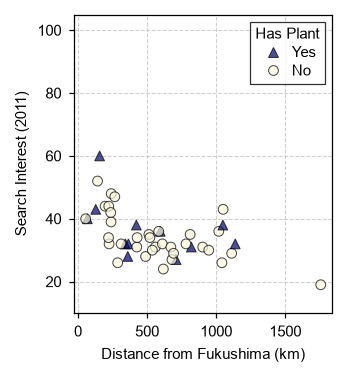

In [5]:
fig, ax = plt.subplots(figsize=(2.2, 2.4), layout="constrained")
distance_scatter(ax, "2011", "Search Interest (2011)", marker_size=22)
plt.show()

### Figure 3d: Search Interest by host status, 2012–2024 (Fukushima excluded)

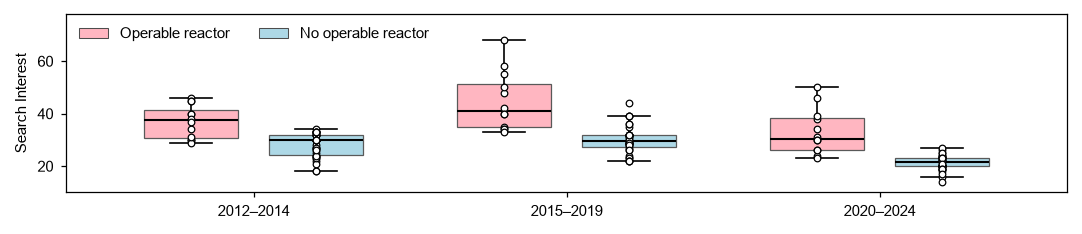

In [6]:
fig, ax = plt.subplots(figsize=(7.1, 1.45), layout="constrained")
for i, (p, label) in enumerate(POST):
    box_points(ax, [d.loc[d[f"host_{p}"] == h, f"search_interest_{p}"] for h in (1, 0)], [i - 0.2, i + 0.2],
               ["lightpink", "lightblue"], width=0.3, size=10)
ax.set_xticks(range(3), [p.replace("-", "–") for p, _ in POST])
ax.set_xlim(-0.6, 2.6)
ax.set_ylim(10, 78)
ax.set_ylabel("Search Interest")
ax.legend(handles=[Patch(facecolor="lightpink", edgecolor="0.3", linewidth=0.5, label="Operable reactor"),
                   Patch(facecolor="lightblue", edgecolor="0.3", linewidth=0.5, label="No operable reactor")],
          loc="upper left", bbox_to_anchor=(0.0, 1.0), ncol=2, frameon=False)
plt.show()

### Supplementary Figure S1: Search Interest against distance from Fukushima, 2004–2010 and 2012–2014

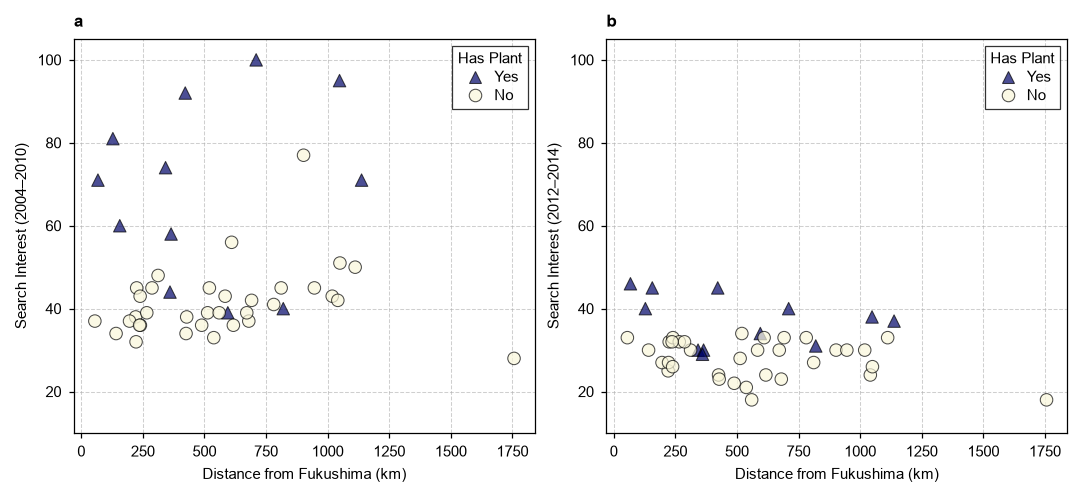

In [7]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(7.1, 3.2), layout="constrained")
distance_scatter(ax1, "2004-2010", "Search Interest (2004–2010)", marker_size=36)
distance_scatter(ax2, "2012-2014", "Search Interest (2012–2014)", marker_size=36)
ax1.set_title("a", loc="left", fontweight="bold", fontsize=8)
ax2.set_title("b", loc="left", fontweight="bold", fontsize=8)
plt.show()